# Download, preparação e inspeção inicial - UCI - Early Stage Diabetes Risk Prediction

Dados de questionários de pacientes do Sylhet Diabetes Hospital, em Bangladesh. A UCI informa 520 registros e 16 atributos. A fonte declara licença CC BY 4.0: mantenha a atribuição ao reutilizar os dados. DOI: https://doi.org/10.24432/C5VG8H.

Fonte: [dataset original](https://archive.ics.uci.edu/dataset/529/early+stage+diabetes+risk+prediction+dataset).

**Objetivo:** baixar os dados, preservar os campos originais, salvar em Parquet e inspecionar sua qualidade e distribuição. Execute as células na ordem apresentada, no ambiente de `ml/`.

Este notebook é didático e não realiza diagnóstico, treinamento ou registro de modelos.

## 1. Bibliotecas e caminhos

As pastas são criadas automaticamente. O Parquet e os arquivos de origem ficam em `data/`, ignorada pelo Git.

In [1]:
from pathlib import Path
from datetime import datetime, timezone
import hashlib
import io
import json
import zipfile

import matplotlib.pyplot as plt
import pandas as pd
import requests
import seaborn as sns
from IPython.display import display

sns.set_theme(style="whitegrid")

# Funciona iniciando o Jupyter na raiz, em ml/ ou em ml/notebooks/.
def find_project_root():
    for candidate in (Path.cwd(), *Path.cwd().parents):
        if (candidate / "ml" / "pyproject.toml").is_file() and (candidate / "README.md").is_file():
            return candidate
    raise FileNotFoundError("Abra o notebook dentro deste repositório.")

PROJECT_ROOT = find_project_root()

DATASET_URL = "https://archive.ics.uci.edu/static/public/529/early%2Bstage%2Bdiabetes%2Brisk%2Bprediction%2Bdataset.zip"
SOURCE_PAGE = "https://archive.ics.uci.edu/dataset/529/early+stage+diabetes+risk+prediction+dataset"
DATA_DIR = PROJECT_ROOT / "data" / "uci-diabetes"
DATA_DIR.mkdir(parents=True, exist_ok=True)
CSV_PATH = DATA_DIR / "diabetes_data_upload.csv"
PARQUET_PATH = DATA_DIR / "diabetes.parquet"
METADATA_PATH = DATA_DIR / "source.json"
TARGET = "class"
EXPECTED_COLUMNS = ["Age","Gender","Polyuria","Polydipsia","sudden weight loss","weakness","Polyphagia","Genital thrush","visual blurring","Itching","Irritability","delayed healing","partial paresis","muscle stiffness","Alopecia","Obesity","class"]
FORCE_DOWNLOAD = False  # True para atualizar o arquivo original.
print(f"Pasta de dados: {DATA_DIR.relative_to(PROJECT_ROOT).as_posix()}")


Pasta de dados: data/uci-diabetes


## 2. Download e leitura

O arquivo existente é reutilizado. Para baixar novamente, altere `FORCE_DOWNLOAD`. O conteúdo recebido é validado antes de substituir o CSV local; uma falha de rede pode ser corrigida executando a célula novamente.

In [2]:
if FORCE_DOWNLOAD or not CSV_PATH.is_file():
    response = requests.get(DATASET_URL, timeout=(15, 60))
    response.raise_for_status()
    # Lê somente o CSV esperado; não extrai caminhos arbitrários do ZIP.
    with zipfile.ZipFile(io.BytesIO(response.content)) as archive:
        members = [name for name in archive.namelist() if Path(name).name == CSV_PATH.name]
        if len(members) != 1:
            raise ValueError("O ZIP não contém um único CSV com o nome esperado.")
        csv_bytes = archive.read(members[0])
    candidate = pd.read_csv(io.BytesIO(csv_bytes))
    if candidate.empty or list(candidate.columns) != EXPECTED_COLUMNS:
        raise ValueError("O arquivo recebido está vazio ou seu esquema mudou. Confira a fonte.")
    temporary_path = CSV_PATH.with_suffix(".csv.part")
    temporary_path.write_bytes(csv_bytes)
    temporary_path.replace(CSV_PATH)
    metadata = {
        "source_page": SOURCE_PAGE,
        "download_url": DATASET_URL,
        "downloaded_at_utc": datetime.now(timezone.utc).isoformat(),
        "csv_sha256": hashlib.sha256(csv_bytes).hexdigest(),
    }
    METADATA_PATH.write_text(json.dumps(metadata, ensure_ascii=False, indent=2), encoding="utf-8")
    print("Download concluído.")
else:
    print("Usando o CSV já disponível.")

data = pd.read_csv(CSV_PATH)
if data.empty or list(data.columns) != EXPECTED_COLUMNS:
    raise ValueError("CSV local vazio ou com colunas inesperadas. Confira o arquivo.")
if TARGET not in data:
    raise ValueError("Coluna alvo ausente.")
expected_classes = {"Positive", "Negative"}
if data[TARGET].isna().any() or set(data[TARGET].unique()) != expected_classes:
    raise ValueError("A coluna alvo contém valores ausentes ou classes inesperadas.")
display(data.head())


Usando o CSV já disponível.


,Age,Gender,Polyuria,Polydipsia,sudden weight loss,weakness,Polyphagia,Genital thrush,visual blurring,Itching,Irritability,delayed healing,partial paresis,muscle stiffness,Alopecia,Obesity,class
0,40,Male,No,Yes,No,Yes,No,No,No,Yes,No,Yes,No,Yes,Yes,Yes,Positive
1,58,Male,No,No,No,Yes,No,No,Yes,No,No,No,Yes,No,Yes,No,Positive
2,41,Male,Yes,No,No,Yes,Yes,No,No,Yes,No,Yes,No,Yes,Yes,No,Positive
3,45,Male,No,No,Yes,Yes,Yes,Yes,No,Yes,No,Yes,No,No,No,No,Positive
4,60,Male,Yes,Yes,Yes,Yes,Yes,No,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Positive


## 3. Preparação e salvamento em Parquet

Nesta etapa, preparação significa converter o CSV em Parquet, preservando linhas, colunas e valores. Não removemos duplicatas, imputamos ausências, codificamos categorias ou normalizamos atributos. Essas decisões ficam para os experimentos posteriores.

In [3]:
temporary_parquet = PARQUET_PATH.with_suffix(".parquet.part")
data.to_parquet(temporary_parquet, engine="pyarrow", index=False)
restored = pd.read_parquet(temporary_parquet, engine="pyarrow")
pd.testing.assert_frame_equal(data, restored)
temporary_parquet.replace(PARQUET_PATH)
print(f"Parquet salvo e conferido: {PARQUET_PATH.relative_to(PROJECT_ROOT).as_posix()}")
print(f"{len(data):,} registros; {len(data.columns)} colunas.")


Parquet salvo e conferido: data/uci-diabetes/diabetes.parquet
520 registros; 17 colunas.


## 4. Estrutura e qualidade dos dados

Observe tipos, valores ausentes e duplicatas. Registros iguais não são automaticamente erros; avalie seu significado antes de removê-los.

In [4]:
data.info()
quality = pd.DataFrame({
    "tipo": data.dtypes.astype(str),
    "ausentes": data.isna().sum(),
    "ausentes_percentual": data.isna().mean().mul(100).round(2),
    "valores_distintos": data.nunique(dropna=False),
})
display(quality)
print(f"Linhas inteiramente duplicadas: {data.duplicated().sum()}")

display(data.describe(include="all").T)


<class 'pandas.DataFrame'>
RangeIndex: 520 entries, 0 to 519
Data columns (total 17 columns):
 #   Column              Non-Null Count  Dtype
---  ------              --------------  -----
 0   Age                 520 non-null    int64
 1   Gender              520 non-null    str  
 2   Polyuria            520 non-null    str  
 3   Polydipsia          520 non-null    str  
 4   sudden weight loss  520 non-null    str  
 5   weakness            520 non-null    str  
 6   Polyphagia          520 non-null    str  
 7   Genital thrush      520 non-null    str  
 8   visual blurring     520 non-null    str  
 9   Itching             520 non-null    str  
 10  Irritability        520 non-null    str  
 11  delayed healing     520 non-null    str  
 12  partial paresis     520 non-null    str  
 13  muscle stiffness    520 non-null    str  
 14  Alopecia            520 non-null    str  
 15  Obesity             520 non-null    str  
 16  class               520 non-null    str  
dtypes: int64

,tipo,ausentes,ausentes_percentual,valores_distintos
Age,int64,0,0.0,51
Gender,str,0,0.0,2
Polyuria,str,0,0.0,2
Polydipsia,str,0,0.0,2
sudden weight loss,str,0,0.0,2
weakness,str,0,0.0,2
Polyphagia,str,0,0.0,2
Genital thrush,str,0,0.0,2
visual blurring,str,0,0.0,2
Itching,str,0,0.0,2


Linhas inteiramente duplicadas: 269


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Age,520.0,NaN,NaN,NaN,48.028846,12.151466,16.0,39.0,47.5,57.0,90.0
Gender,520,2,Male,328,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Polyuria,520,2,No,262,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Polydipsia,520,2,No,287,NaN,NaN,NaN,NaN,NaN,NaN,NaN
sudden weight loss,520,2,No,303,NaN,NaN,NaN,NaN,NaN,NaN,NaN
weakness,520,2,Yes,305,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Polyphagia,520,2,No,283,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Genital thrush,520,2,No,404,NaN,NaN,NaN,NaN,NaN,NaN,NaN
visual blurring,520,2,No,287,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Itching,520,2,No,267,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 5. Balanceamento das classes

As proporções são calculadas diretamente do arquivo. O balanceamento influencia a escolha de métricas e a futura separação dos dados.

,quantidade,percentual
Negativo,200,38.46
Positivo,320,61.54


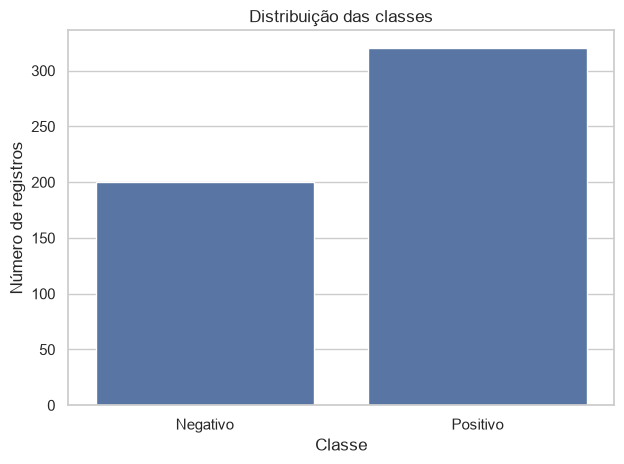

In [5]:
class_labels = {"Negative":"Negativo","Positive":"Positivo"}
counts = data[TARGET].value_counts().sort_index()
balance = pd.DataFrame({"quantidade": counts, "percentual": counts.div(len(data)).mul(100).round(2)})
balance.index = [class_labels[str(value)] for value in balance.index]
display(balance)
ax = sns.barplot(x=balance.index, y=balance["quantidade"], color="#4c72b0")
ax.set(title="Distribuição das classes", xlabel="Classe", ylabel="Número de registros")
plt.tight_layout()
plt.show()


## 6. Distribuição das variáveis

Os gráficos são descritivos: diferenças entre grupos e correlações não demonstram causalidade.

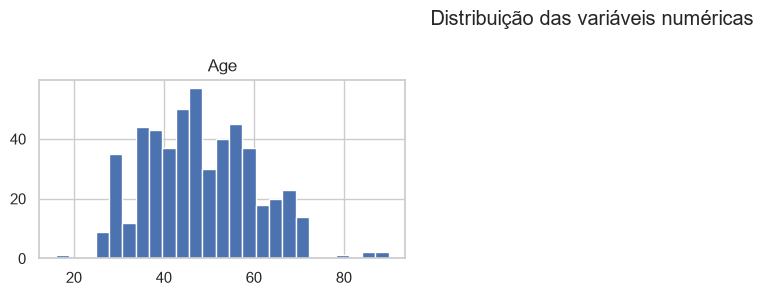

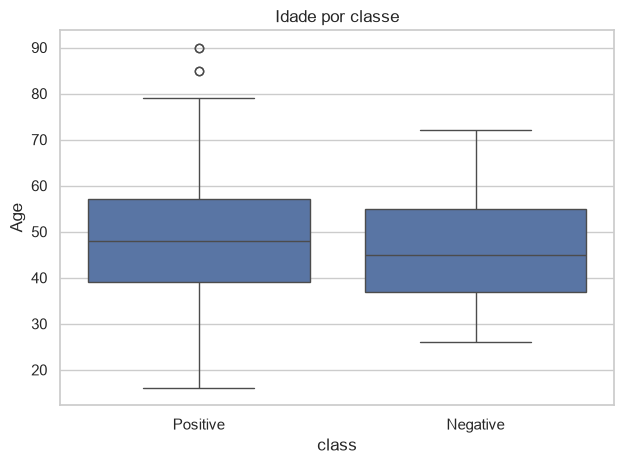

In [6]:
numeric_columns = [name for name in data.select_dtypes(include="number").columns if name not in {TARGET, "PatientID"}]
if numeric_columns:
    data[numeric_columns].hist(bins=25, figsize=(12, max(3, 3 * ((len(numeric_columns) + 2) // 3))), layout=((len(numeric_columns) + 2) // 3, 3))
    plt.suptitle("Distribuição das variáveis numéricas")
    plt.tight_layout()
    plt.show()

if "Age" in data:
    sns.boxplot(data=data, x=TARGET, y="Age")
    plt.title("Idade por classe")
    plt.tight_layout()
    plt.show()


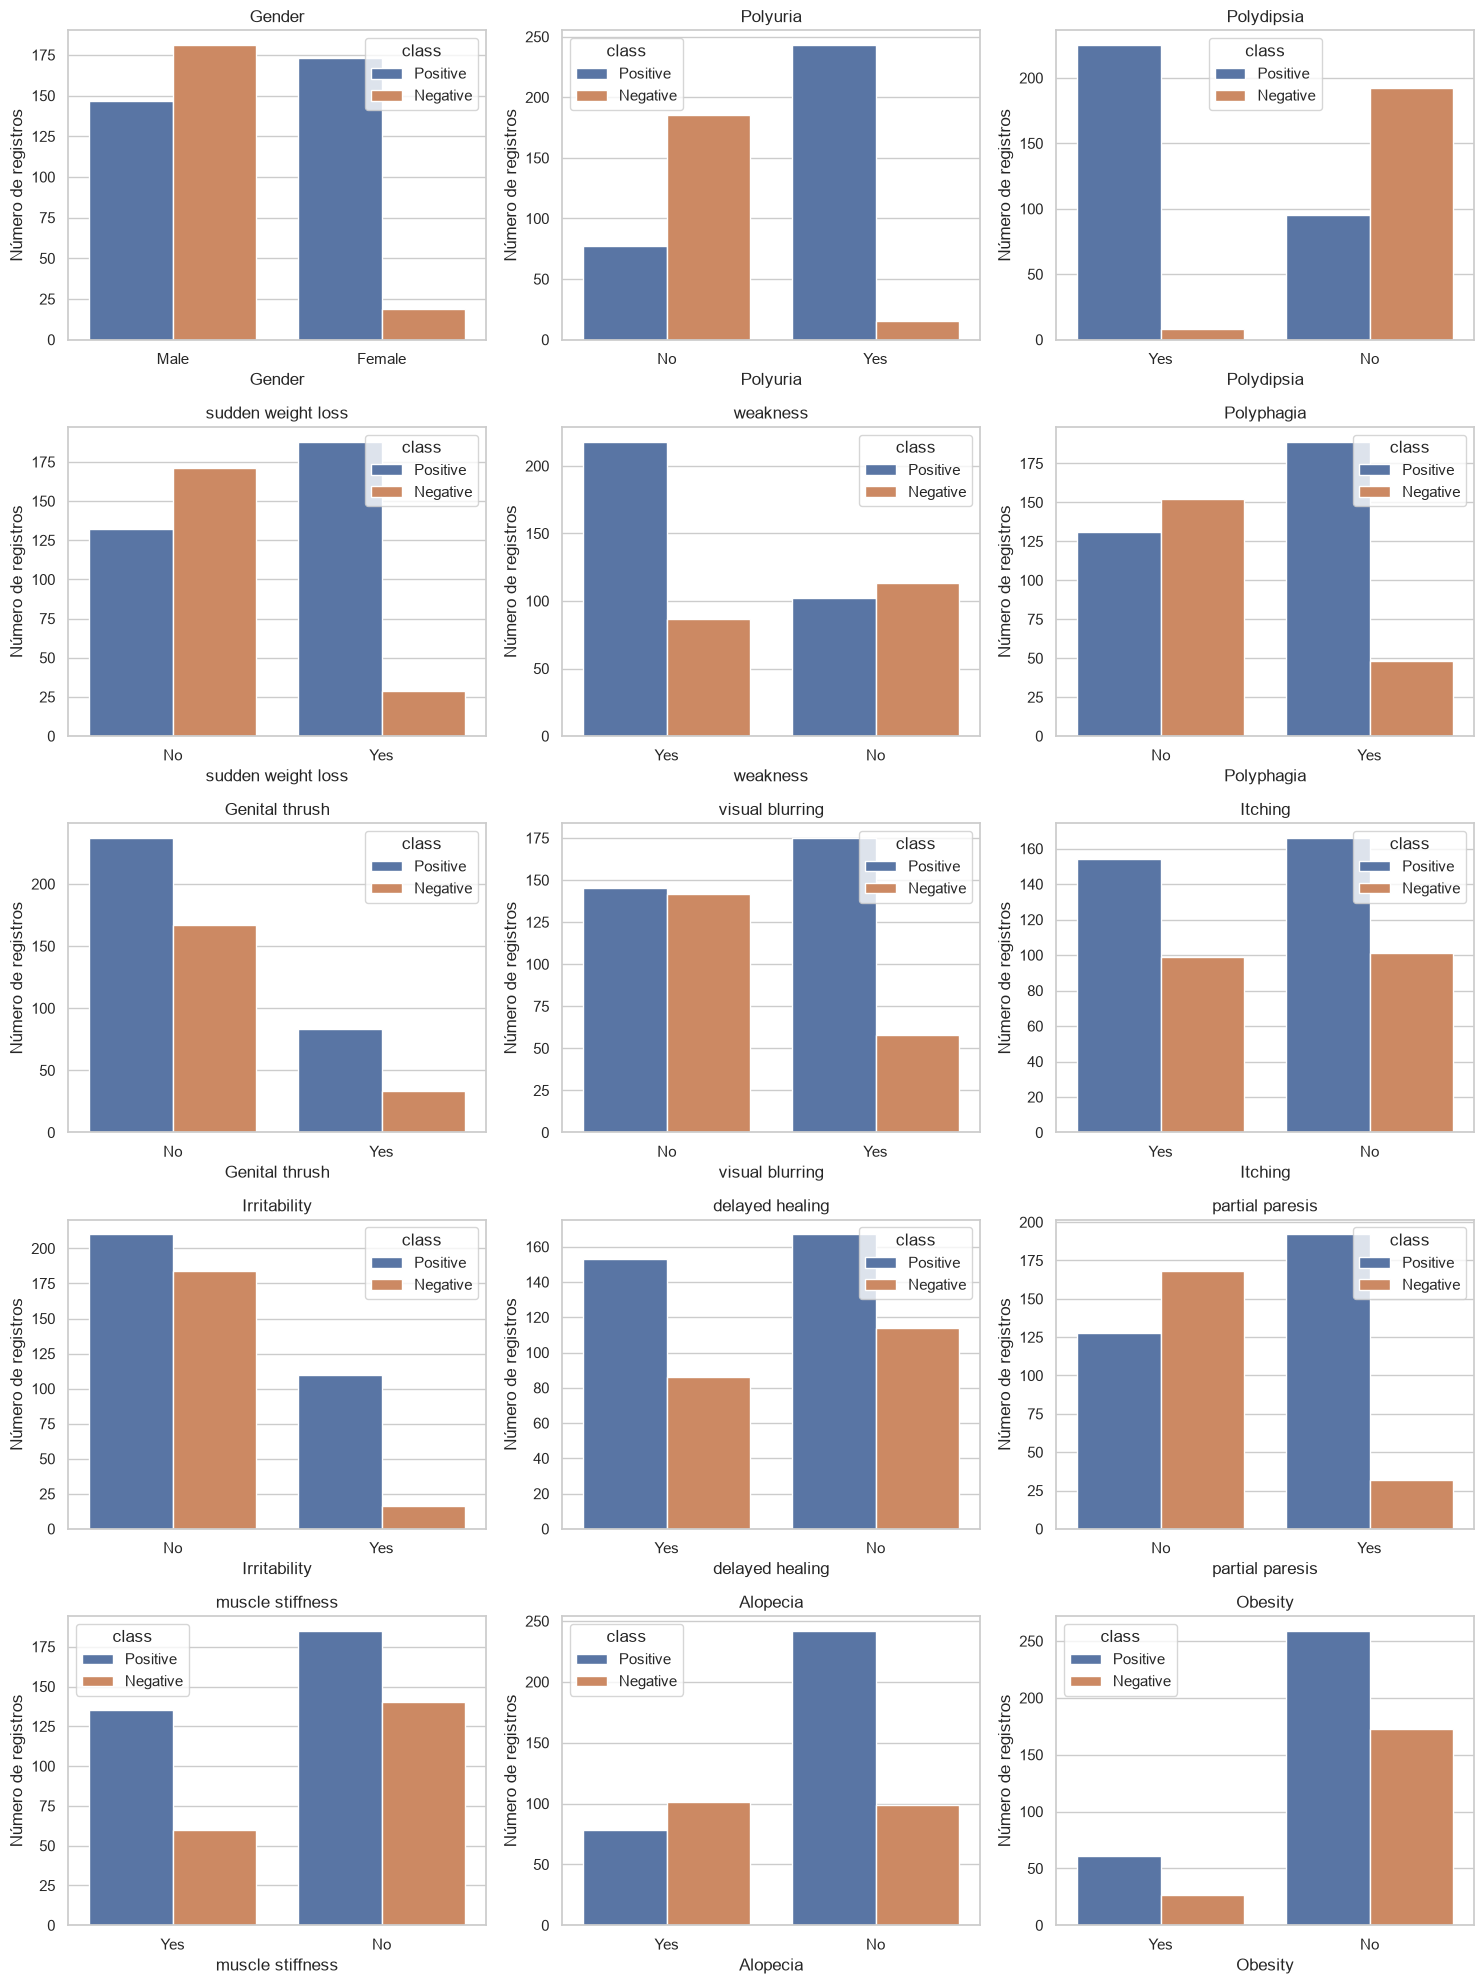

In [7]:
categorical_columns = [name for name in data.select_dtypes(exclude="number").columns if name != TARGET]
fig, axes = plt.subplots((len(categorical_columns) + 2) // 3, 3, figsize=(15, 4 * ((len(categorical_columns) + 2) // 3)), squeeze=False)
for ax, column in zip(axes.flat, categorical_columns):
    sns.countplot(data=data, x=column, hue=TARGET, ax=ax)
    ax.set_title(column)
    ax.set_ylabel("Número de registros")
for ax in list(axes.flat)[len(categorical_columns):]:
    ax.set_visible(False)
plt.tight_layout()
plt.show()


## 7. Perguntas para a próxima etapa

- Há classes desbalanceadas ou padrões que merecem investigação?
- Quais campos são compreensíveis e fáceis de preencher em uma interface em português?
- Há ausências, zeros ou duplicatas que precisam de uma decisão documentada?
- Quais limitações da origem dos dados precisam acompanhar os resultados?

O Parquet produzido será a entrada para o futuro notebook de treinamento. A inspeção completa pode usar todos os dados para conhecer o arquivo; decisões de seleção de atributos e ajuste do modelo deverão preservar um conjunto de teste independente.